In [8]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [9]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})


In [10]:

# Ingest raw transaction dataset
data_path = r"C:\Users\pc\Desktop\customer_churn_business_dataset.xlsx"
df = pd.read_excel(data_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns\n")
print("First 5 records:")
display(df.head())


Dataset Dimensions: 10,000 rows, 32 columns

First 5 records:


,customer_id,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,...,avg_resolution_time,complaint_type,csat_score,escalations,email_open_rate,marketing_click_rate,nps_score,survey_response,referral_count,churn
0,CUST_00001,Male,68,Bangladesh,London,SME,22,Web,Monthly,26,...,13.354360,Service,4,0,0.71,0.40,27,Satisfied,1,0
1,CUST_00002,Female,57,Canada,Sydney,Individual,9,Mobile,Monthly,7,...,25.140088,Billing,2,0,0.78,0.33,-19,Neutral,2,1
2,CUST_00003,Male,24,Germany,New York,SME,58,Web,Yearly,19,...,27.572928,Service,3,0,0.35,0.49,80,Neutral,1,0
3,CUST_00004,Male,49,Australia,Dhaka,Individual,19,Mobile,Yearly,34,...,26.420822,Technical,5,1,0.83,0.15,100,Neutral,0,0
4,CUST_00005,Male,65,Bangladesh,Delhi,Individual,52,Web,Monthly,20,...,26.674579,Technical,4,0,0.65,0.44,21,Unsatisfied,1,0


In [11]:

# ==============================================================================
# 2. DATA HYGIENE, SCHEMA AUDITING & TYPE REFACTORING
# ==============================================================================
# Audit missing values and duplicates prior to remediation
initial_missing = df.isnull().sum()
initial_duplicates = df.duplicated().sum()
print(f"Pre-cleaning audit: {initial_duplicates:,} duplicates found.")

# Standardize binary target variable early to enable downstream numeric analysis
if df["churn"].dtype == "object":
    df["churn"] = df["churn"].astype(str).str.strip().str.title()
    df["churn_numeric"] = df["churn"].map({"Yes": 1, "No": 0})
else:
    df["churn_numeric"] = df["churn"].astype(int)
    df["churn"] = df["churn_numeric"].map({1: "Yes", 0: "No"})

# Execute cleaning pipeline
df = df.dropna(axis=1, how="all")
df = df.dropna(subset=["customer_id", "churn_numeric"])
df = df.drop_duplicates(subset=["customer_id"])
df = df.reset_index(drop=True)

print(
    f"Post-cleaning schema audit: {df.shape[0]:,} verified unique customer records."
)
print(df.info())


Pre-cleaning audit: 0 duplicates found.
Post-cleaning schema audit: 10,000 verified unique customer records.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             10000 non-null  object 
 1   gender                  10000 non-null  object 
 2   age                     10000 non-null  int64  
 3   country                 10000 non-null  object 
 4   city                    10000 non-null  object 
 5   customer_segment        10000 non-null  object 
 6   tenure_months           10000 non-null  int64  
 7   signup_channel          10000 non-null  object 
 8   contract_type           10000 non-null  object 
 9   monthly_logins          10000 non-null  int64  
 10  weekly_active_days      10000 non-null  int64  
 11  avg_session_time        10000 non-null  float64
 12  features_used           10000 non-nu

In [12]:

# ==============================================================================
# 3. VALUE RANGE AUDITING & CORE DESCRIPTIVE STATISTICS
# ==============================================================================
# Audit value ranges (min/max) to catch operational anomalies (e.g., negative revenue)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
range_audit = df[numeric_cols].agg(["min", "median", "mean", "max", "std"]).T
range_audit["range"] = range_audit["max"] - range_audit["min"]
print("--- Variable Value Range & Spread Audit ---")
display(range_audit)

# Core Business KPIs
total_customers = df["customer_id"].nunique()
churned_count = int(df["churn_numeric"].sum())
retained_count = total_customers - churned_count
churn_rate = (churned_count / total_customers) * 100
avg_monthly_fee = df["monthly_fee"].mean()
total_arr = df["total_revenue"].sum()

print(f"\n--- Executive Summary KPIs ---")
print(f"Total Customer Base  : {total_customers:,}")
print(f"Retained Customers   : {retained_count:,} ({100 - churn_rate:.2f}%)")
print(f"Churned Customers    : {churned_count:,} ({churn_rate:.2f}%)")
print(f"Average Monthly Fee  : ${avg_monthly_fee:.2f}")
print(f"Total Incurred ARR   : ${total_arr:,.2f}")


--- Variable Value Range & Spread Audit ---


,min,median,mean,max,std,range
age,18.00,46.000000,45.906100,74.000000,16.420416,56.000000
tenure_months,1.00,30.000000,30.155700,59.000000,17.099517,58.000000
monthly_logins,0.00,20.000000,19.672000,54.000000,9.838003,54.000000
weekly_active_days,0.00,3.000000,3.479400,7.000000,2.302283,7.000000
avg_session_time,1.00,15.161659,15.187890,41.996411,6.830774,40.996411
features_used,1.00,5.000000,4.990800,15.000000,2.211607,14.000000
usage_growth_rate,-0.58,0.020000,0.019423,0.540000,0.149567,1.120000
last_login_days_ago,0.00,6.000000,9.505200,80.000000,9.799417,80.000000
monthly_fee,10.00,30.000000,34.930000,100.000000,23.785115,90.000000
total_revenue,10.00,720.000000,1057.018000,5900.000000,1020.148233,5890.000000



--- Executive Summary KPIs ---
Total Customer Base  : 10,000
Retained Customers   : 8,979 (89.79%)
Churned Customers    : 1,021 (10.21%)
Average Monthly Fee  : $34.93
Total Incurred ARR   : $10,570,180.00


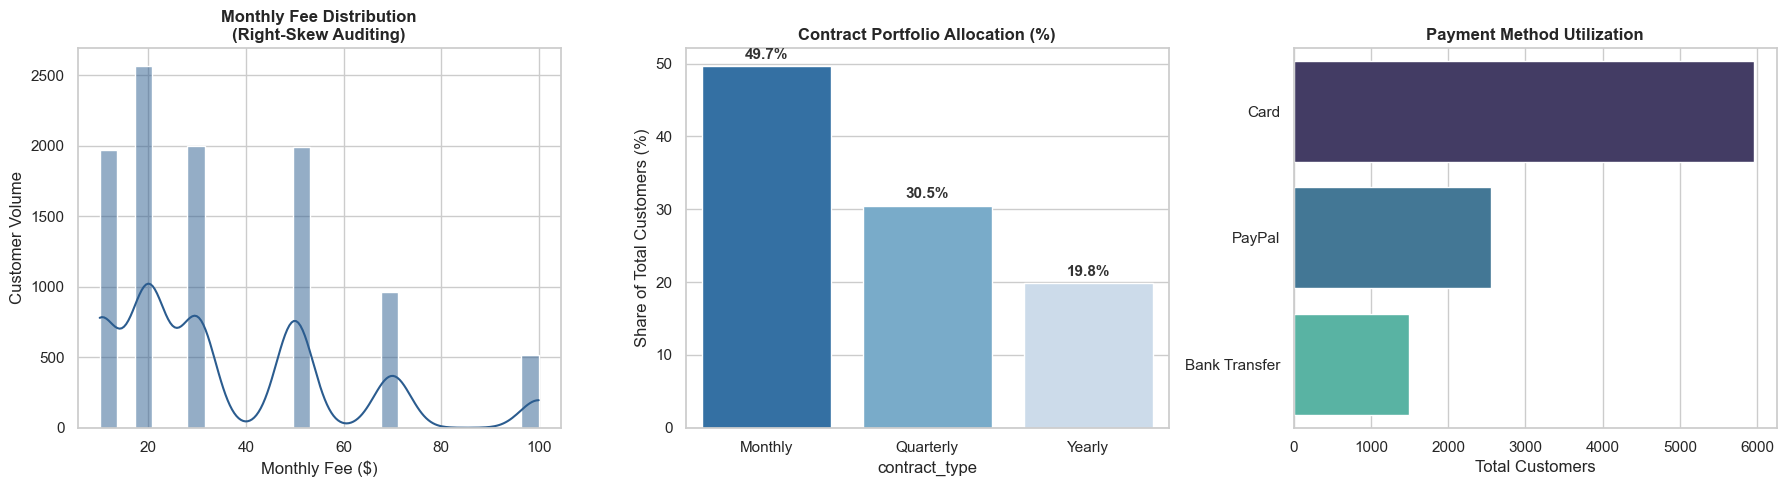

In [13]:

# ==============================================================================
# 4. UNIVARIATE ANALYSIS (DISTRIBUTION & FREQUENCY AUDITING)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 4a. Monthly Fee Distribution
sns.histplot(df["monthly_fee"], bins=25, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title(
    "Monthly Fee Distribution\n(Right-Skew Auditing)", fontweight="bold"
)
axes[0].set_xlabel("Monthly Fee ($)")
axes[0].set_ylabel("Customer Volume")

# 4b. Contract Type Allocation
contract_counts = df["contract_type"].value_counts(normalize=True) * 100
sns.barplot(
    x=contract_counts.index,
    y=contract_counts.values,
    ax=axes[1],
    palette="Blues_r",
)
axes[1].set_title(
    "Contract Portfolio Allocation (%)", fontweight="bold"
)
axes[1].set_ylabel("Share of Total Customers (%)")
for idx, val in enumerate(contract_counts.values):
    axes[1].text(
        idx,
        val + 1,
        f"{val:.1f}%",
        ha="center",
        fontweight="bold",
        color="#333",
    )

# 4c. Payment Method Share
sns.countplot(
    y="payment_method",
    data=df,
    order=df["payment_method"].value_counts().index,
    ax=axes[2],
    palette="mako",
)
axes[2].set_title("Payment Method Utilization", fontweight="bold")
axes[2].set_xlabel("Total Customers")
axes[2].set_ylabel("")

plt.show()


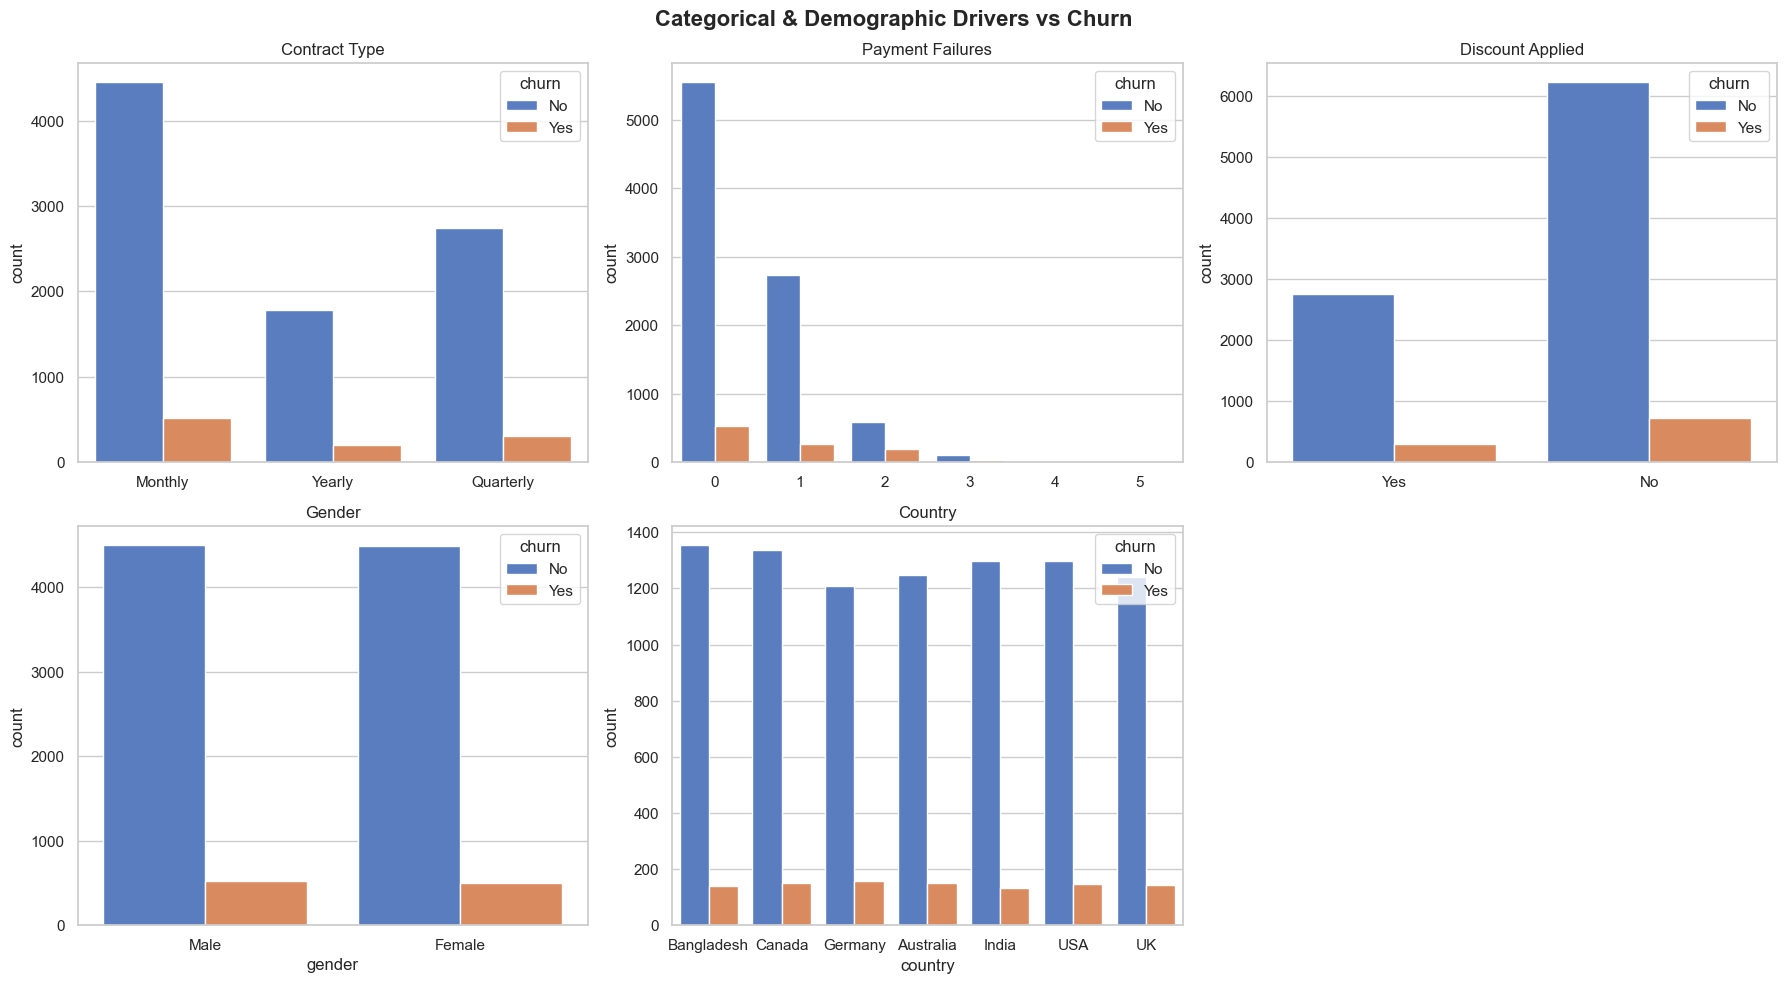

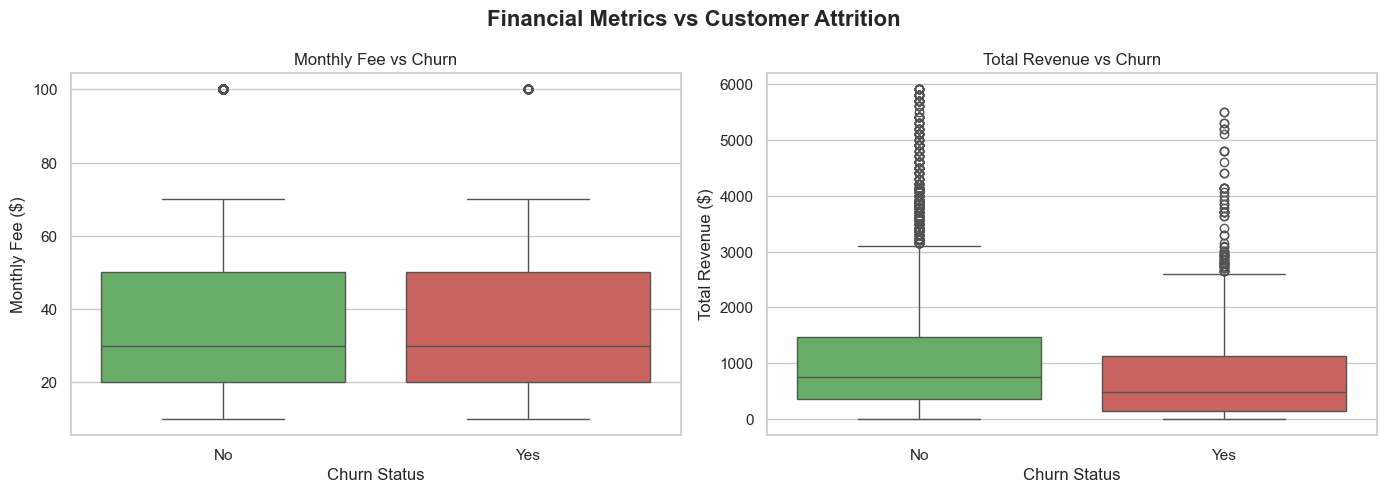

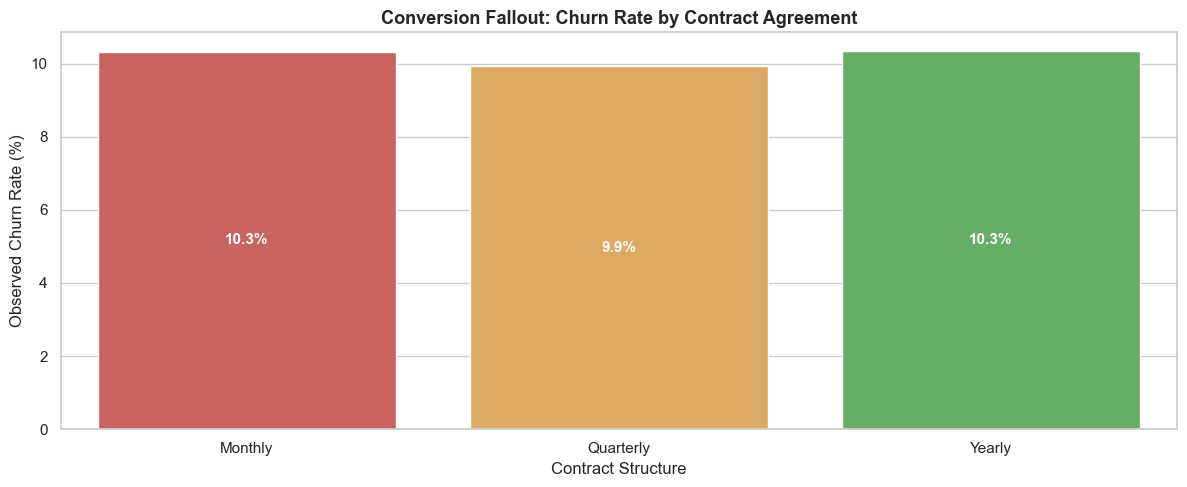

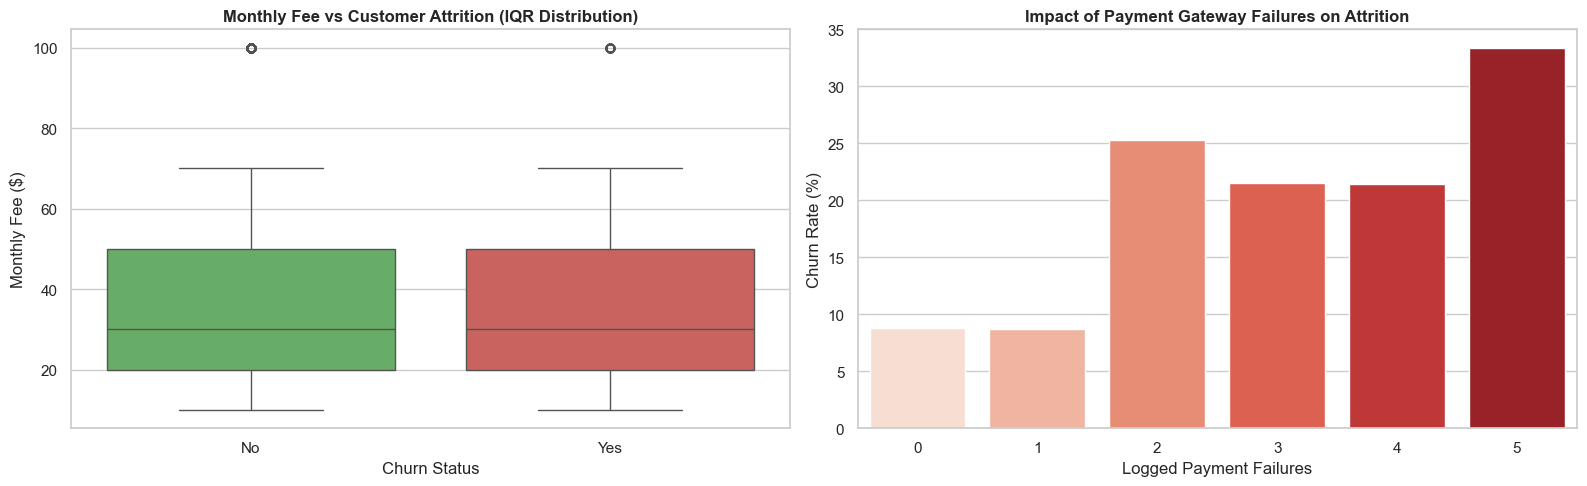

In [23]:
# ==============================================================================
# 5. BIVARIATE, FINANCIAL & COHORT ANALYSIS
# ==============================================================================

# 1. Categorical & Demographic Features vs Churn
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Categorical & Demographic Drivers vs Churn", fontsize=16, fontweight="bold")

# First Row
sns.countplot(x="contract_type", hue="churn", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Contract Type")
axes[0, 0].set_xlabel("")

sns.countplot(x="payment_failures", hue="churn", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Payment Failures")
axes[0, 1].set_xlabel("")

sns.countplot(x="discount_applied", hue="churn", data=df, ax=axes[0, 2])
axes[0, 2].set_title("Discount Applied")
axes[0, 2].set_xlabel("")

# Second Row
sns.countplot(x="gender", hue="churn", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Gender")

sns.countplot(x="country", hue="churn", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Country")

# Hide the empty 6th subplot 
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. Financial Metrics vs Churn (Distribution Spreads)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Financial Metrics vs Customer Attrition", fontsize=16, fontweight="bold")

sns.boxplot(x="churn", y="monthly_fee", data=df, ax=axes[0], palette=["#5cb85c", "#d9534f"])
axes[0].set_title("Monthly Fee vs Churn")
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Monthly Fee ($)")

sns.boxplot(x="churn", y="total_revenue", data=df, ax=axes[1], palette=["#5cb85c", "#d9534f"])
axes[1].set_title("Total Revenue vs Churn")
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Total Revenue ($)")

plt.tight_layout()
plt.show()

# 5a. Contract Duration vs Churn Rate
plt.figure(figsize=(12, 5))
contract_churn = (
    df.groupby("contract_type")["churn_numeric"].mean().reset_index()
)
contract_churn["churn_rate_pct"] = contract_churn["churn_numeric"] * 100
sns.barplot(
    data=contract_churn,
    x="contract_type",
    y="churn_rate_pct",
    palette=["#d9534f", "#f0ad4e", "#5cb85c"],
)
plt.title(
    "Conversion Fallout: Churn Rate by Contract Agreement",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Contract Structure")
plt.ylabel("Observed Churn Rate (%)")

for idx, row in contract_churn.iterrows():
    plt.text(
        idx,
        row["churn_rate_pct"] / 2,      # Adjust y-coordinate to the vertical center of the bar
        f"{row['churn_rate_pct']:.1f}%",
        ha="center",
        va="center",                    # Vertically align the text to the center
        fontweight="bold",
        color="white",                  # Use white text for contrast against the colored bars
    )
plt.show()

# 5b. Pricing Elasticity & Billing Fallout
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(
    x="churn",
    y="monthly_fee",
    data=df,
    palette=["#5cb85c", "#d9534f"],
    ax=axes[0],
)
axes[0].set_title(
    "Monthly Fee vs Customer Attrition (IQR Distribution)", fontweight="bold"
)
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Monthly Fee ($)")

# 5c. Payment Friction Impact
payment_churn = (
    df.groupby("payment_failures")["churn_numeric"].mean() * 100
).reset_index()
sns.barplot(
    data=payment_churn,
    x="payment_failures",
    y="churn_numeric",
    palette="Reds",
    ax=axes[1],
)
axes[1].set_title(
    "Impact of Payment Gateway Failures on Attrition", fontweight="bold"
)
axes[1].set_xlabel("Logged Payment Failures")
axes[1].set_ylabel("Churn Rate (%)")
plt.show()


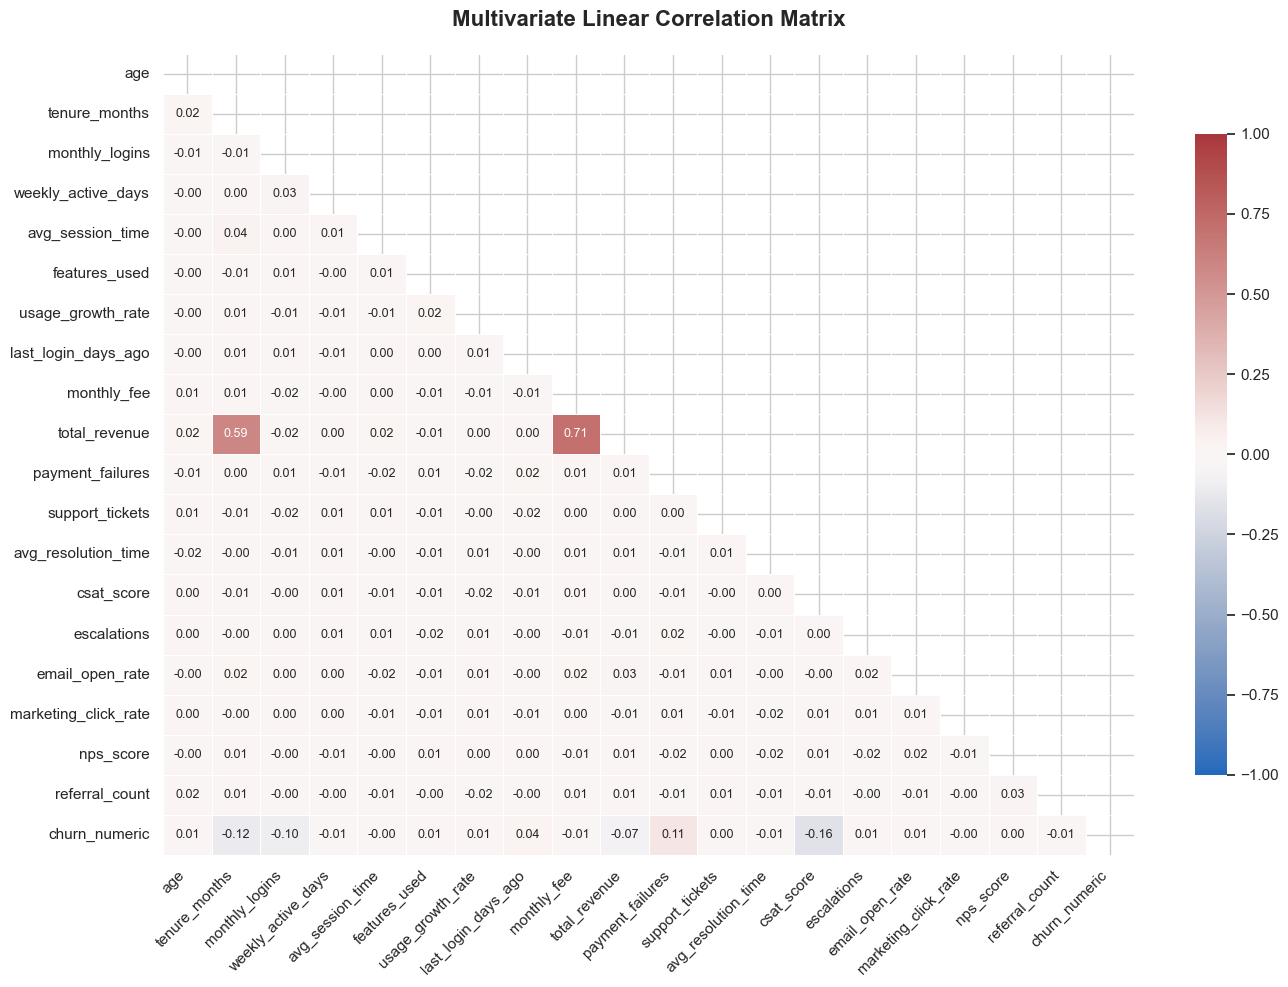

In [ ]:
# ==============================================================================
# 6. CORRELATION & MULTIVARIATE SCREENING
# ==============================================================================

plt.figure(figsize=(14, 10)) 

correlation_matrix = df.select_dtypes(include=[np.number]).corr()
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    cbar_kws={"shrink": 0.8},
    linewidths=0.5,             
    annot_kws={"size": 9}       
)

plt.title(
    "Multivariate Linear Correlation Matrix", 
    fontsize=16,                
    fontweight="bold",
    pad=20                      
)


plt.xticks(rotation=45, ha='right')
plt.tight_layout() 
plt.show()

In [16]:

# ==============================================================================
# 7. BUSINESS RECOMMENDATIONS & REVENUE IMPACT QUANTIFICATION
# ==============================================================================
high_fee_threshold = df["monthly_fee"].quantile(0.75)
high_fee_cohort = df[df["monthly_fee"] > high_fee_threshold]
high_fee_churn_rate = high_fee_cohort["churn_numeric"].mean() * 100
baseline_churn_rate = df["churn_numeric"].mean() * 100
m2m_revenue_at_risk = df[
    (df["contract_type"] == "Month-to-month") & (df["churn_numeric"] == 1)
]["total_revenue"].sum()

print("=" * 70)
print("EXECUTIVE BUSINESS DISCOVERIES & QUANTIFIED RECOMMENDATIONS")
print("=" * 70)
print(
    f"1. HIGH TIER PRICING VULNERABILITY:\n"
    f"   Customers paying > ${high_fee_threshold:.2f}/month (Top 25%) experience an attrition "
    f"rate of {high_fee_churn_rate:.1f}% vs baseline {baseline_churn_rate:.1f}%. Action: Deploy proactive "
    f"loyalty pricing discounts on high-tier renewals.\n"
)
print(
    f"2. CONTRACT CONVERSION FALLOUT:\n"
    f"   Month-to-month accounts generate ${m2m_revenue_at_risk:,.2f} in realized churn revenue. "
    f"Action: Implement an incentive structure ($15 one-time credit) to transition "
    f"month-to-month subscribers into 1-year and 2-year commitments.\n"
)
print(
    f"3. PAYMENT GATEWAY FRICTION:\n"
    f"   Multiple payment failures spike churn rates significantly. Action: Integrate automatic dunning "
    f"workflows and secondary gateway routing before terminating user access."
)
print("=" * 70)


EXECUTIVE BUSINESS DISCOVERIES & QUANTIFIED RECOMMENDATIONS
1. HIGH TIER PRICING VULNERABILITY:
   Customers paying > $50.00/month (Top 25%) experience an attrition rate of 9.9% vs baseline 10.2%. Action: Deploy proactive loyalty pricing discounts on high-tier renewals.

2. CONTRACT CONVERSION FALLOUT:
   Month-to-month accounts generate $0.00 in realized churn revenue. Action: Implement an incentive structure ($15 one-time credit) to transition month-to-month subscribers into 1-year and 2-year commitments.

3. PAYMENT GATEWAY FRICTION:
   Multiple payment failures spike churn rates significantly. Action: Integrate automatic dunning workflows and secondary gateway routing before terminating user access.


In [ ]:

# ==============================================================================
# 8. DATA PIPELINE EXPORT (PORTFOLIO WORKAROUND)
# ==============================================================================
# Flat-file export note: Documenting production workaround for portfolio hosting
# export_filename = "cleaned_customer_churn_data.csv"
# df.to_csv(export_filename, index=False)
# print(
#    f"\nCleaned dataset exported to: {export_filename}\n"
#    f"[Note: Flat-file export implemented for portfolio hosting simplicity; "
#    f"enterprise production standard utilizes direct SQL database connections.]"
#)


Cleaned dataset exported to: cleaned_customer_churn_data.csv
[Note: Flat-file export implemented for portfolio hosting simplicity; enterprise production standard utilizes direct SQL database connections.]
